In [1]:
from main import *

In [2]:
def plot_trajectoire_new(res,dx = 1e-13):
    """Énergies, positions des billes et centroïde en fonction du temps."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=False)

    axes[0].plot(res.t, res.e_kin_class_kelvin, label="Cinétique classique", lw=0.8)
    axes[0].plot(res.t, res.e_pot_kelvin, label="Potentielle", lw=0.8)
    axes[0].plot(res.t, res.e_pot_kelvin + res.e_kin_class_kelvin, label="Totale", lw=0.8)
    axes[0].set_ylabel("Énergie (K)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_title("Énergies en fonction du temps")

    xmax = np.ceil(np.max(np.abs(res.X)) / dx) * dx
    edges = np.arange(-xmax, xmax + dx, dx)
    centers = 0.5 * (edges[:-1] + edges[1:])
    nb = len(centers)

    counts, _ = np.histogram(res.X.ravel(), bins=edges)
    density = counts / (counts.sum() * dx) 

    axes[1].bar(centers, density, width=dx, align="center")
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("densité")
    # axes[1].plot(res.t, res.X, lw=0.5, alpha=0.6)
    # axes[1].set_ylabel("$x_s$ (m)")
    # axes[1].set_title(f"Positions des {res.P} beads")

    axes[2].plot(res.t, res.centroid, color="k", lw=1)
    axes[2].axhline(0, color="gray", ls="--", lw=0.5)
    axes[2].set_ylabel(r"Centroïde $\bar{x}$ (m)")
    axes[2].set_xlabel("Temps (s)")
    axes[2].set_title("Centre du polymère")

    fig.tight_layout()
    return fig

def question_5(n_steps=100000, P=1024, xc=0.0, C=0.8, T_facteur=0.2):
    """On impose la position xc du centroïde : il ne doit pas bouger au cours de la dynamique."""
    sim, res = run_simulation(
        n_steps=n_steps, P=P, gamma=None, alpha=1 / 100, xc=xc, C=C, T_facteur=T_facteur, seed=None
    )
    plot_trajectoire_new(res)

    print(f"Centroïde moyenne: {(np.mean(res.centroid) * 1e10):.2e} Angström")
    print(f"Centroïde écart-type: {(np.std(res.centroid) * 1e10):.2e} Angström")
    print(f"Force moyenne sur le centroïde f_c = {np.mean(res.fc):.3e} N")
    plt.show()



V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 512 | n_steps = 400000 | alpha = 0.01
dt = 9.343e-18 s | gamma = 1.070e+14 s^-1
Simulation terminée.
Centroïde moyenne: 1.71e-12 Angström
Centroïde écart-type: 2.63e-12 Angström
Force moyenne sur le centroïde f_c = 8.799e-12 N


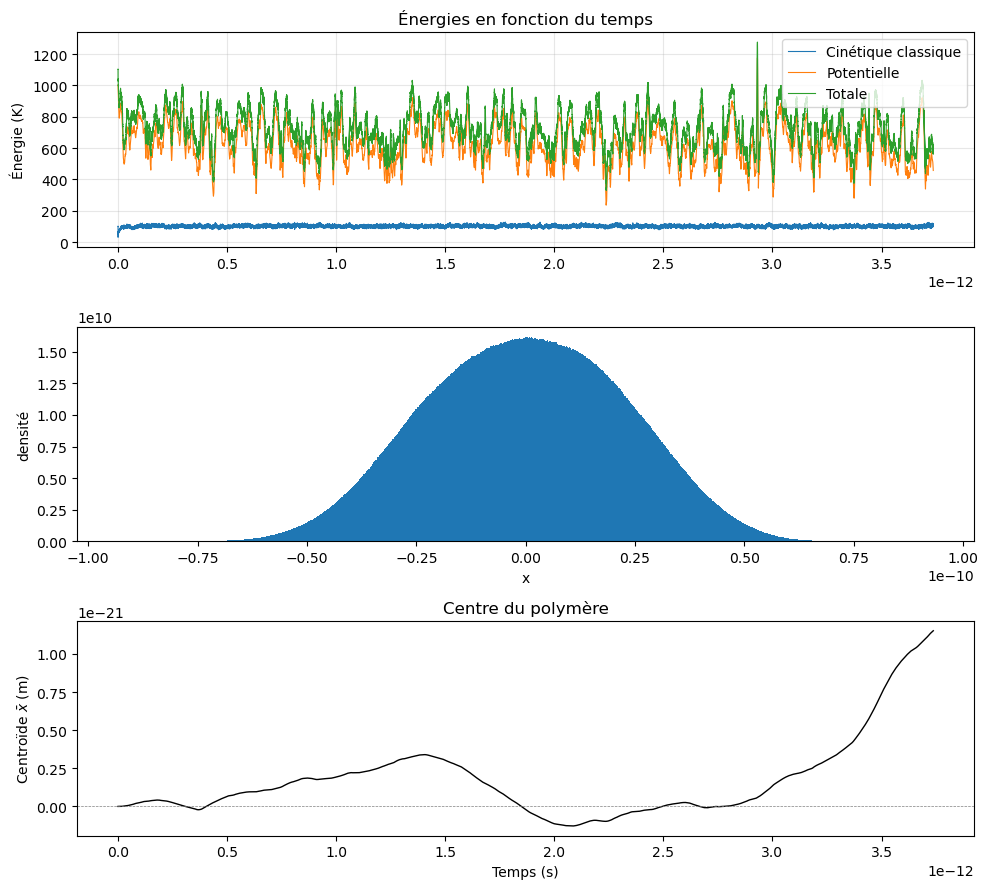

In [8]:
question_5(n_steps=400000, P=512, xc=0, C=0.3, T_facteur=0.2)

In [17]:
_STYLE_COURBE = dict(
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor="#1f77b4",
    linewidth=2,
    color="#1f77b4",
)

def _style_axe(ax, xlabel, ylabel, title):
    ax.set_xlabel(xlabel, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=11, fontweight="bold")
    ax.set_title(title, fontsize=12, pad=12)
    ax.grid(True, which="major", color="#d3d3d3", linestyle="--", linewidth=0.7)
    ax.grid(True, which="minor", color="#f0f0f0", linestyle=":", linewidth=0.5)

def question_6_new(
    n_xc=10,
    xc_max=0.05e-9,
    P=512,
    n_steps=100000,
    C=0.8,
    T_facteur=0.2,
):
    """Calcul de f_c pour différentes valeurs de x_c puis intégration
    pour obtenir le potentiel effectif E_p(x_c) = -∫ f_c dx_c."""
    X_c = np.linspace(0, xc_max, n_xc)
    dX = X_c[1] - X_c[0]
    F_c = []
    E_p = [0]
    for x_c in X_c:
        sim, res = run_simulation(
            n_steps=n_steps, P=P, gamma=None, alpha=1 / 100, xc=x_c, C=C, T_facteur=T_facteur, seed=None
        )
        F_c.append(np.mean(res.fc[len(res.fc) // 2:]))
        E_p.append(E_p[-1] - F_c[-1] * dX)
    E_p = np.array(E_p[: len(X_c)])

    fig, axes = plt.subplots(2, 1, figsize=(8, 5), dpi=150)

    axes[0].plot(X_c, F_c, label=r"$f_c$", **_STYLE_COURBE)
    axes[0].axhline(0, color="gray", ls="--", lw=0.8)
    _style_axe(axes[0], r"Position centroïde $x_c$ (m)", r"$f_c$ (N)",
               rf"Valeur moyenne de $f_c$ à chaque position $x_c$ (C={C}, T={T_facteur}$V_0/k_B$)")
    axes[0].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10)

    axes[1].plot(X_c, E_p, label=r"$E_p$", **_STYLE_COURBE)
    _style_axe(axes[1], r"Position centroïde $x_c$ (m)", r"$E_p$ (J)",
               r"Potentiel effectif $E_p$ à chaque position $x_c$")
    axes[1].legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10)

    fig.tight_layout()

    V0 = sim.pot.V0
    barriere = E_p[0] - np.min(E_p)
    print(f"Hauteur de barrière effective : {barriere:.3e} J = {barriere / V0:.3f} V0 "
          f"(x_c du minimum = {X_c[np.argmin(E_p)] * 1e10:.3f} Angström)")
    plt.show()

V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1

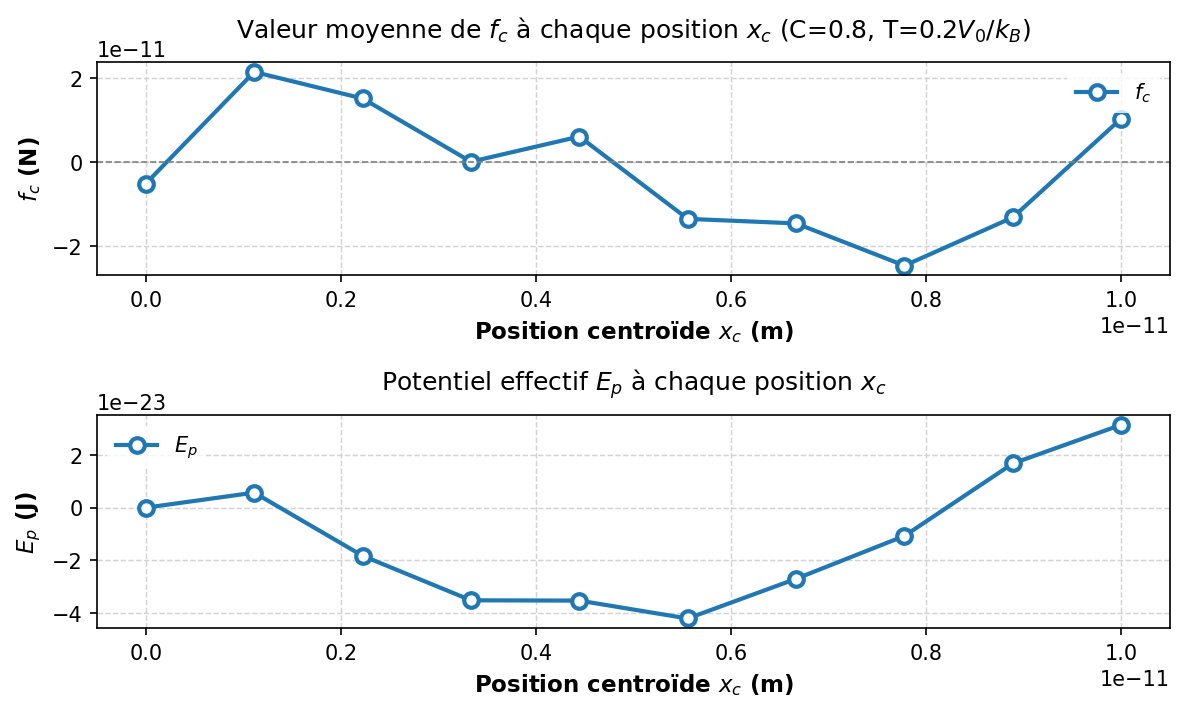

In [11]:
question_6(
    n_xc=10,
    xc_max=0.01e-9,
    P=1024,
    n_steps=100000,
    C=0.8,
    T_facteur=0.2,
)

V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1

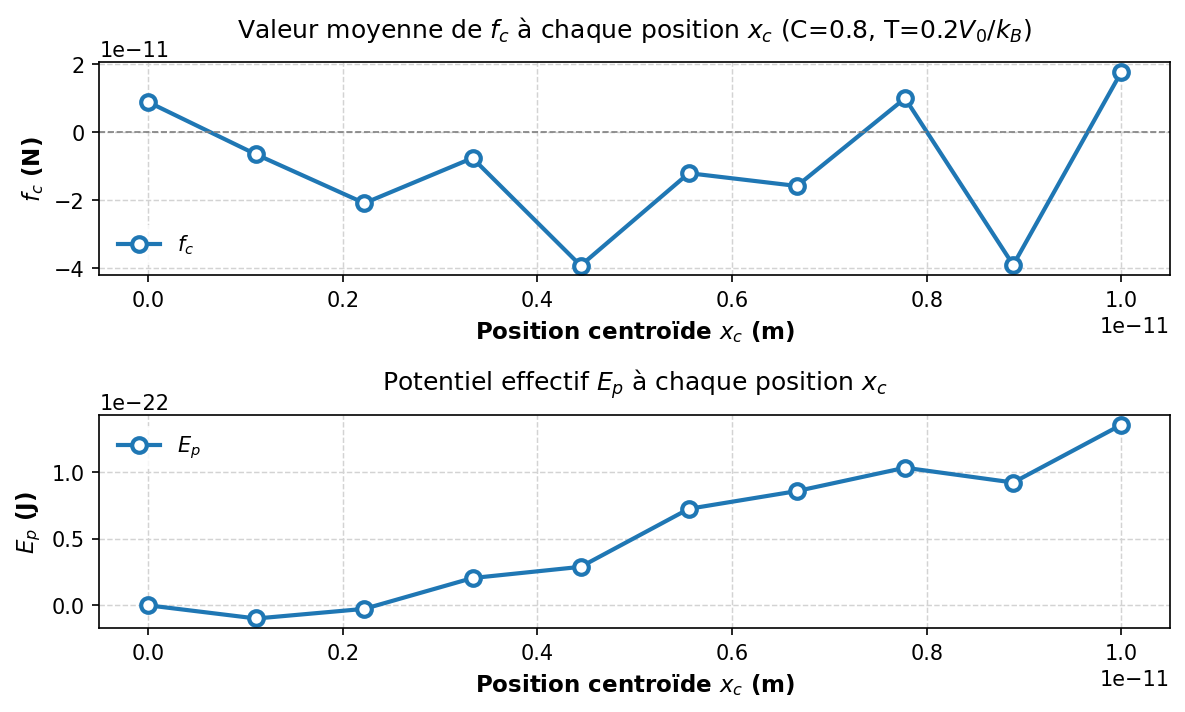

In [18]:
question_6_new(
    n_xc=10,
    xc_max=0.01e-9,
    P=1024,
    n_steps=100000,
    C=0.8,
    T_facteur=0.2,
)

V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1
Simulation terminée.
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 1.246e-17 s | gamma = 8.028e+13 s^-1

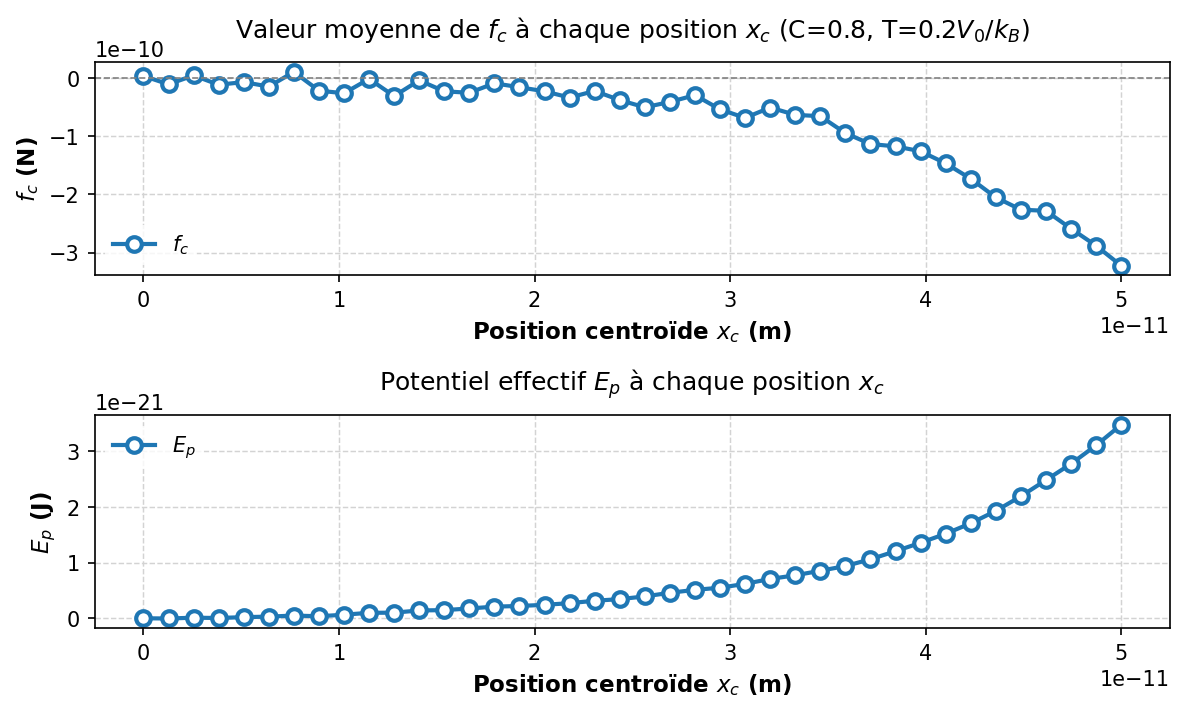

In [ ]:
question_6(
    n_xc=40,
    xc_max=0.05e-9,
    P=1024,
    n_steps=100000,
    C=0.8,
    T_facteur=0.2,
)

V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 100.33 K
P = 1024 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+

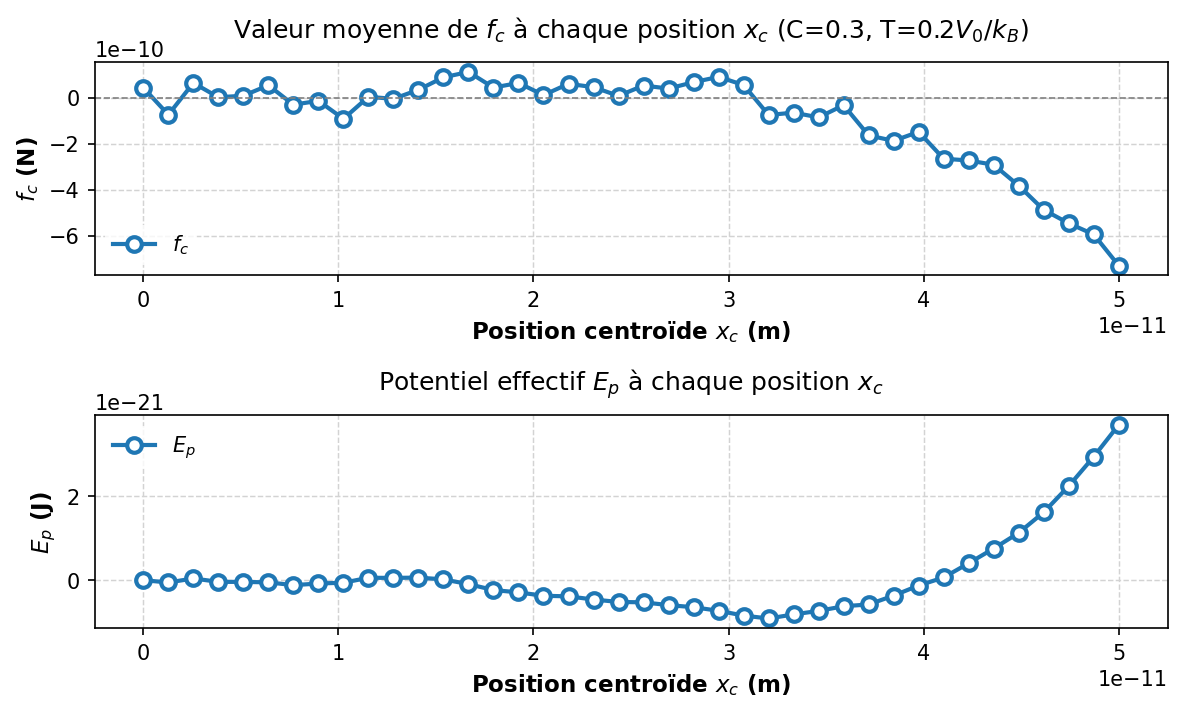

In [10]:
question_6(
    n_xc=40,
    xc_max=0.05e-9,
    P=1024,
    n_steps=100000,
    C=0.3,
    T_facteur=0.2,
)

V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1
Simulation terminée.
V0 = 6.93e-21 J (0.04 eV) | T = 200.66 K
P = 512 | n_steps = 100000 | alpha = 0.01
dt = 4.671e-18 s | gamma = 2.141e+14 s^-1

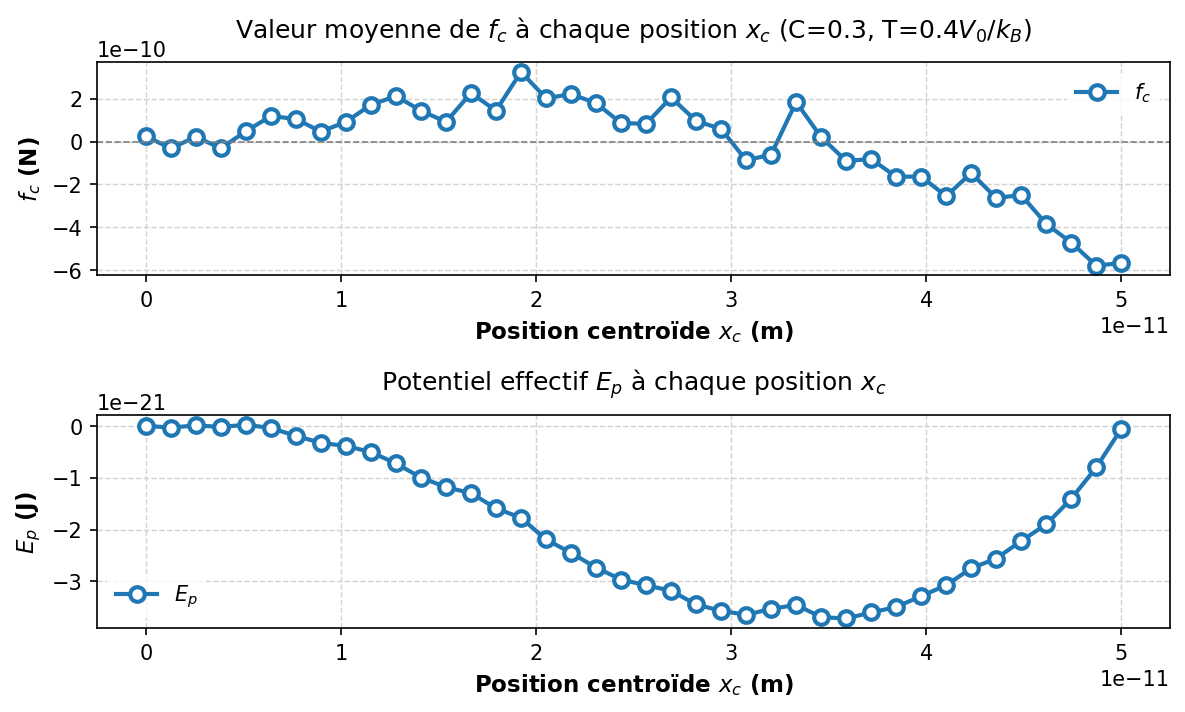

In [ ]:
question_6(
    n_xc=40,
    xc_max=0.05e-9,
    P=1024,
    n_steps=100000,
    C=0.3,
    T_facteur=0.4,
)